### Astrostatistic Lecture 22-23

In [45]:
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
from astroML.utils import completeness_contamination
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import corner
plt.rcParams['figure.facecolor'] = 'black' #custom plot stuff
plt.rcParams['axes.facecolor'] = 'black'
plt.rcParams['axes.edgecolor'] = 'white'         
plt.rcParams['axes.labelcolor'] = 'white'  
plt.rcParams['text.color'] = 'white'  
plt.rcParams['xtick.color'] = 'white'           
plt.rcParams['ytick.color'] = 'white'

#Used the galaxy/quasar dataset
data = pd.read_csv('/home/ricca/astrostat/astrostatistics_bicocca_2026/solutions/galaxyquasar.csv') #load data
data

,u,g,r,i,z,class,z1,zerr
0,18.97213,18.53676,18.58280,18.34936,18.29215,QSO,0.522819,0.000155
1,19.24592,17.47646,16.47817,16.04472,15.68851,GALAXY,0.122846,0.000028
2,19.43536,17.70268,16.91565,16.58327,16.39128,GALAXY,0.000000,0.000000
3,19.31626,18.18312,17.39591,16.94549,16.65395,GALAXY,0.147435,0.000009
4,19.28828,19.11188,18.88937,18.80013,18.49183,QSO,2.011455,0.000631
...,...,...,...,...,...,...,...,...
49995,19.37295,18.12382,17.39886,16.98503,16.70585,GALAXY,0.113016,0.000011
49996,18.52021,16.88262,16.03280,15.56884,15.22454,GALAXY,0.085063,0.000014
49997,18.62718,17.30876,16.87371,16.62399,16.42296,GALAXY,0.054429,0.000008
49998,19.55140,18.27711,17.62101,17.21947,17.03347,GALAXY,0.112571,0.000009


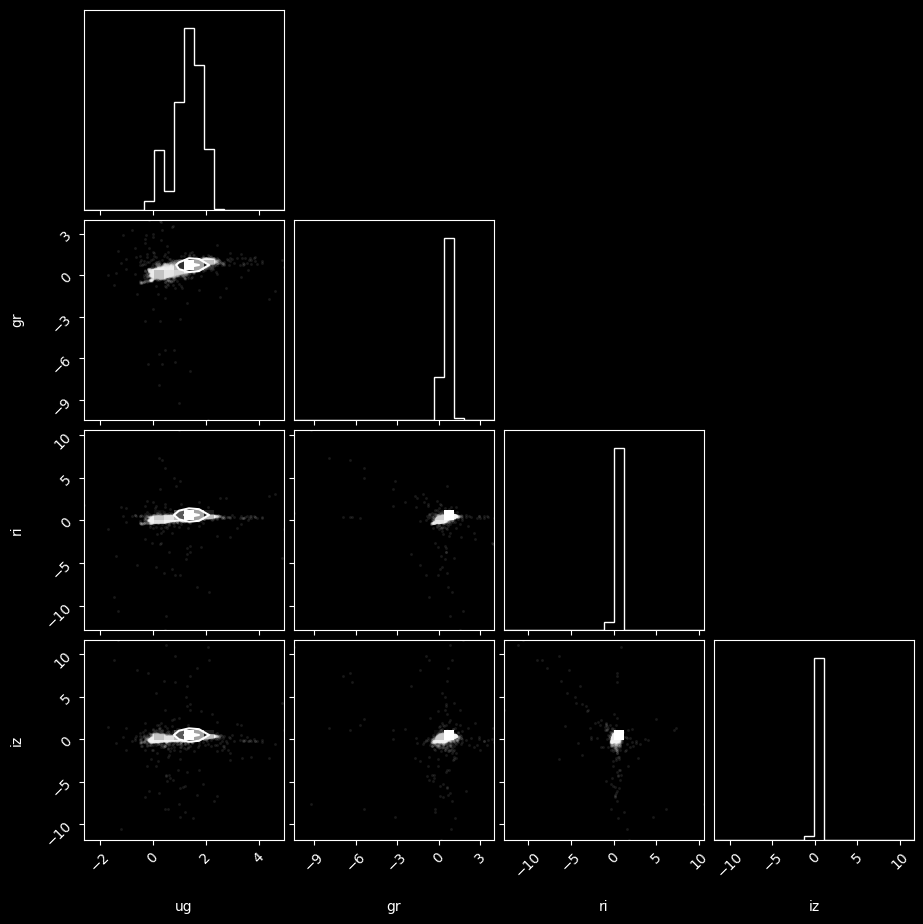

In [46]:
#unpack the data into arrays (same as in lecture 19)
z = data['z'].values
u = data['u'].values
g = data['g'].values
r = data['r'].values
i = data['i'].values
z = data['z'].values
cls = data['class'].values
Target = (np.asarray(cls) != "GALAXY").astype("float32")

#arrays for the color combinations
u_g = u - g
g_r = g - r
r_i = r - i
i_z = i - z

staring_x = np.array([u_g, g_r, r_i, i_z]).T #array for the color combinations 

#recall the shape of the data we are working on 
corner.corner(staring_x, labels=['ug', 'gr', 'ri', 'iz'])
plt.show()

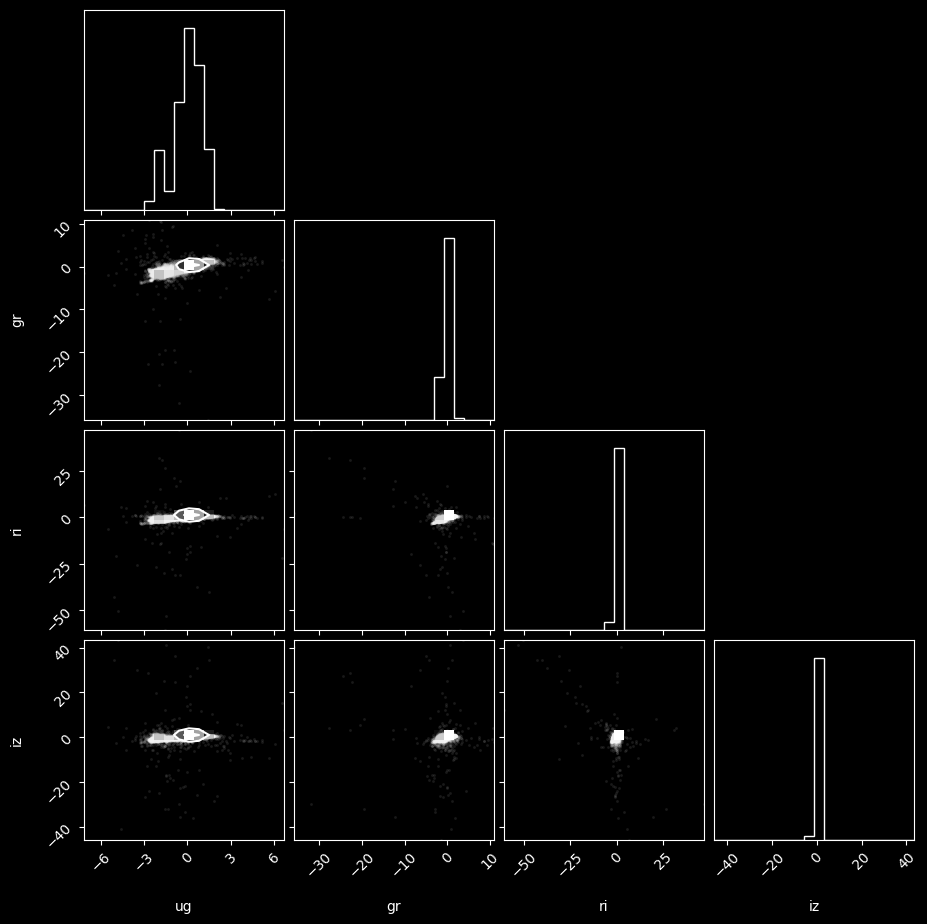

In [47]:
#the first step is to scale our data  now our points are alle centered around 0 
staring_x = (staring_x - np.mean(staring_x, axis=0)) / np.std(staring_x, axis=0)
corner.corner(staring_x, labels=['ug', 'gr', 'ri', 'iz'])
plt.show()

**Strategy.** I divide the data into three sets: training, validation, and testing. The test set is used only once, at the very end, to estimate final performance. I do not use cross-validation because the dataset is large; a single validation set of 3,000 samples provides a sufficiently stable estimate while incurring a much lower computational cost.

**Optimized metric.** I optimize the ROC-AUC beacuse it's independent of the decision threshold, which I determine separately. For the test set, I also report additional, non-optimized metrics: accuracy, precision, recall, F1-score, and the confusion matrix.

In [48]:
#the first idea i have is to train a neural network classifier using keras
#first split the data in train, validation and test

X_train, X_test, y_train, y_test = train_test_split(staring_x, Target, test_size=0.2, random_state=42)
X_train, X_valid = X_train[:-3000], X_train[-3000:]
y_train, y_valid = y_train[:-3000], y_train[-3000:]

X_train = X_train[:, :, np.newaxis]
X_valid = X_valid[:,  :, np.newaxis]
X_test = X_test[:, :, np.newaxis]

#now i can try to build the acutual model, it's for classification so i use a sigmoid activation function

model = keras.models.Sequential([
    keras.layers.Input(shape=(4,)),
    keras.layers.Dense(64, activation="sigmoid"),
    keras.layers.Dense(32, activation="sigmoid"),
    keras.layers.Dense(16, activation="sigmoid"),
    keras.layers.Dense(1, activation="sigmoid"),
])  

print(model.summary())

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

None


In [49]:
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
clf = model.fit(X_train, y_train, epochs=5, validation_data=(X_valid, y_valid))

Epoch 1/5
1157/1157 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9532 - loss: 0.1484 - val_accuracy: 0.9840 - val_loss: 0.0664
Epoch 2/5
1157/1157 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9826 - loss: 0.0673 - val_accuracy: 0.9853 - val_loss: 0.0633
Epoch 3/5
1157/1157 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9834 - loss: 0.0659 - val_accuracy: 0.9857 - val_loss: 0.0630
Epoch 4/5
1157/1157 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9832 - loss: 0.0654 - val_accuracy: 0.9853 - val_loss: 0.0597
Epoch 5/5
1157/1157 ━━━━━━━━━━━━━━━━━━━━ 1s 718us/step - accuracy: 0.9833 - loss: 0.0648 - val_accuracy: 0.9857 - val_loss: 0.0600


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


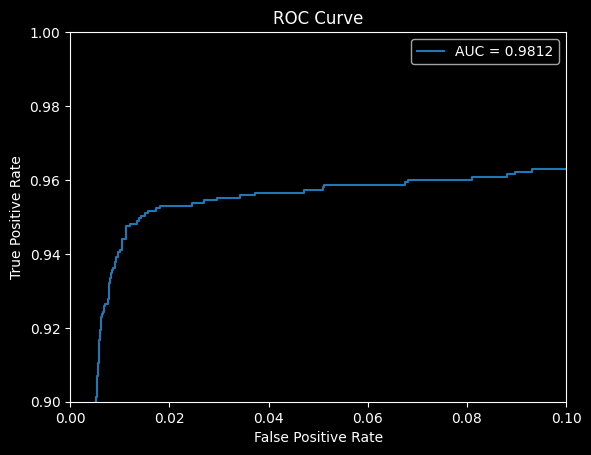

              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      8572
         1.0       0.94      0.94      0.94      1428

    accuracy                           0.98     10000
   macro avg       0.97      0.96      0.97     10000
weighted avg       0.98      0.98      0.98     10000

Confusion matrix: 
 [[8494   78]
 [  91 1337]]
ROC-AUC: 0.981
For reference the GMM in lecure 19 had a score of 0.989


In [51]:
#now i can test the model with the test set
y_proba = model.predict(X_test).ravel()      # probability for a given class
y_pred = (y_proba > 0.5).astype(int)         # Remember that 0 = galacy and 1=quasar

fpr, tpr, thresh = roc_curve(y_test, y_proba)
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.plot(fpr, tpr, label='AUC = %0.4f' % auc(fpr, tpr))
plt.xlim(0, 0.1)
plt.ylim(0.9, 1)
plt.legend()
plt.show()

print(classification_report(y_test, y_pred))    #other metrics report
print('Confusion matrix: \n',confusion_matrix(y_test, y_pred))
print(f'ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}')
print('For reference the GMM in lecure 19 had a score of 0.989')